In [1]:

# ARTI 502 - Deep Learning Assignment 2
# Training and Testing CNN with CIFAR-10 using PyTorch

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

from torch.utils.data import DataLoader

# Check PyTorch version
print("PyTorch Version:", torch.__version__)

# Check GPU availability
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using Device:", device)


PyTorch Version: 2.11.0+cu130
Using Device: cuda


In [2]:

# Task 1: Getting the CIFAR Dataset

DATA_PATH = "./data"

# Convert images to tensors
transform = transforms.ToTensor()

# Download training dataset
train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=True,
    transform=transform
)

# Download testing dataset
test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=True,
    transform=transform
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("CIFAR-10 Dataset Loaded Successfully!")
print("Training Images:", len(train_dataset))
print("Testing Images:", len(test_dataset))
print("Classes:", train_dataset.classes)


100%|██████████| 170M/170M [31:20<00:00, 90.6kB/s]


CIFAR-10 Dataset Loaded Successfully!
Training Images: 50000
Testing Images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [3]:

# Task 2: Defining the CNN Architecture

class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()

        # First Convolutional Layer
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=16,
            kernel_size=3,
            padding=1
        )

        # Second Convolutional Layer
        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Max Pooling Layer
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Fully Connected Layers
        self.fc1 = nn.Linear(32 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

        # Activation Function
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        # Flatten feature maps
        x = torch.flatten(x, 1)

        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x


# Initialize the model
model = CNNModel().to(device)

print("CNN Model Architecture:")
print(model)


CNN Model Architecture:
CNNModel(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)


In [4]:

# Verify CNN Input and Output Shapes

images, labels = next(iter(train_loader))

images = images.to(device)

outputs = model(images)

print("Input Shape:", images.shape)
print("Output Shape:", outputs.shape)

assert outputs.shape == (images.shape[0], 10), \
    "Incorrect output shape!"

print("CNN Architecture Verified Successfully!")


Input Shape: torch.Size([32, 3, 32, 32])
Output Shape: torch.Size([32, 10])
CNN Architecture Verified Successfully!


In [5]:

# Task 2: Training Function

def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Record loss and correct predictions
        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Training function defined successfully!")


Training function defined successfully!


In [6]:

# Task 2: Testing / Evaluation Function

def evaluate_model(model, test_loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    # Disable gradient calculations during testing
    with torch.no_grad():

        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Calculate correct predictions
            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_loss = running_loss / total
    test_accuracy = 100 * correct / total

    return test_loss, test_accuracy


print("Testing function defined successfully!")


Testing function defined successfully!


In [7]:

# Verify Training and Testing Functions

print("Training function:", callable(train_one_epoch))
print("Testing function:", callable(evaluate_model))

assert callable(train_one_epoch)
assert callable(evaluate_model)

print("\nBoth functions are ready for Task 5!")


Training function: True
Testing function: True

Both functions are ready for Task 5!


In [8]:

# Task 3: Inspect CIFAR-10 Dataset

# Get one batch from the training DataLoader
images, labels = next(iter(train_loader))

print("Images Tensor Shape:", images.shape)
print("Labels Tensor Shape:", labels.shape)

print("\nBatch Size:", images.shape[0])
print("Number of Channels:", images.shape[1])
print("Image Height:", images.shape[2])
print("Image Width:", images.shape[3])

print("\nData Type:", images.dtype)
print("Pixel Value Range:", images.min().item(),
      "to", images.max().item())

print("\nFirst 10 Labels:", labels[:10].tolist())


Images Tensor Shape: torch.Size([32, 3, 32, 32])
Labels Tensor Shape: torch.Size([32])

Batch Size: 32
Number of Channels: 3
Image Height: 32
Image Width: 32

Data Type: torch.float32
Pixel Value Range: 0.0 to 1.0

First 10 Labels: [5, 9, 8, 9, 0, 2, 5, 2, 7, 0]


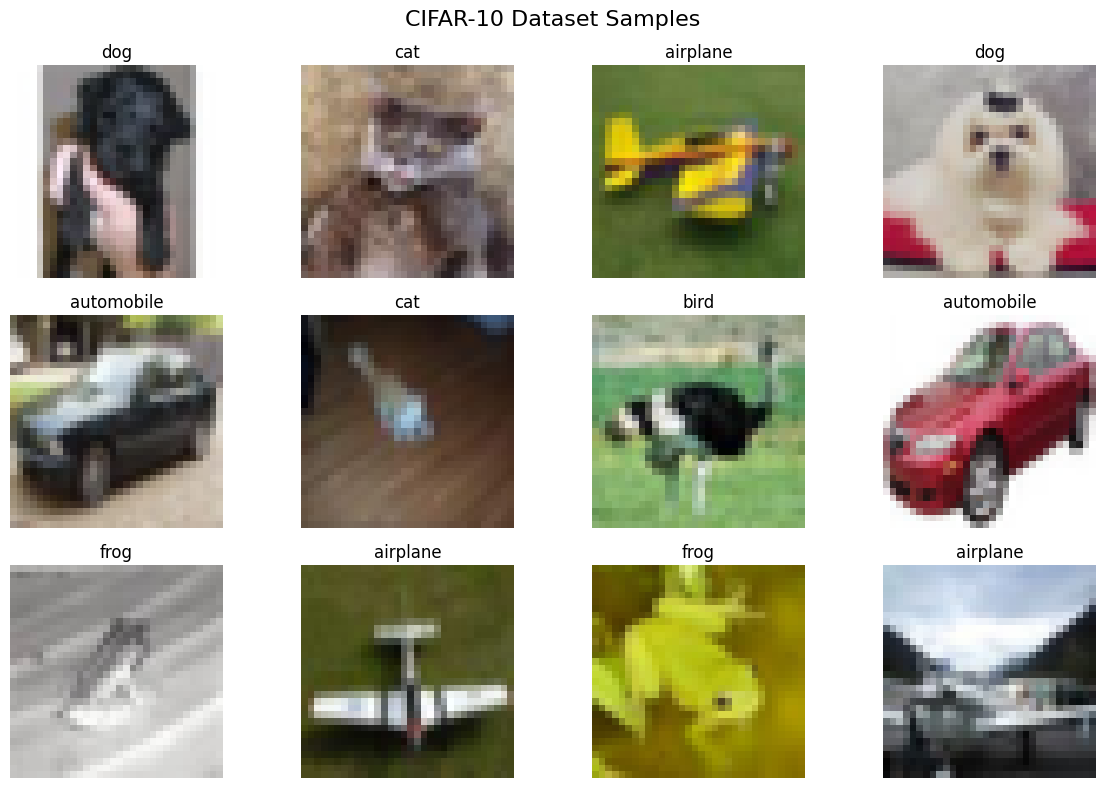

In [9]:

# Task 3: Visualize CIFAR-10 Images

import matplotlib.pyplot as plt

# CIFAR-10 class names
classes = train_dataset.classes

# Get a batch of images
images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)

    # Change tensor format from CxHxW to HxWxC
    image = images[i].permute(1, 2, 0).numpy()

    plt.imshow(image)
    plt.title(classes[labels[i].item()])
    plt.axis("off")

plt.suptitle("CIFAR-10 Dataset Samples", fontsize=16)
plt.tight_layout()
plt.show()


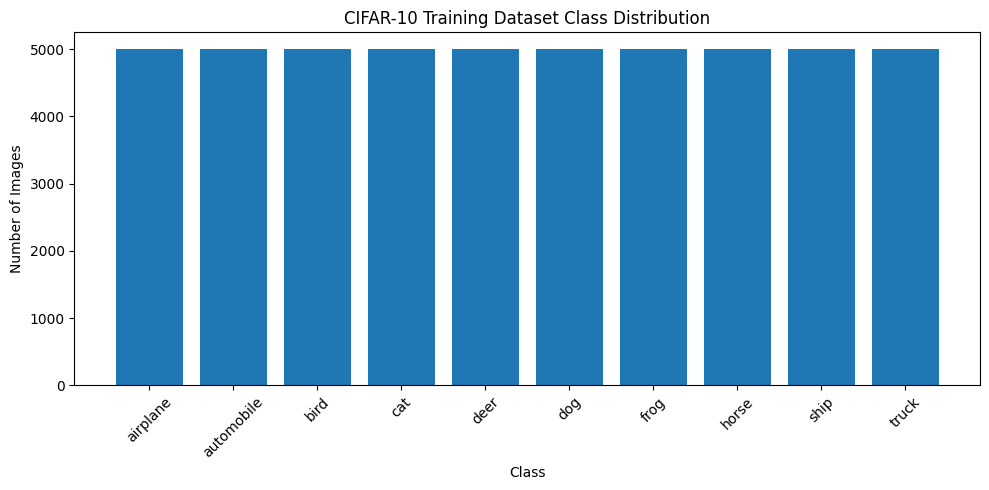

airplane: 5000 images
automobile: 5000 images
bird: 5000 images
cat: 5000 images
deer: 5000 images
dog: 5000 images
frog: 5000 images
horse: 5000 images
ship: 5000 images
truck: 5000 images


In [10]:

# Task 3: CIFAR-10 Class Distribution

import numpy as np

labels_array = np.array(train_dataset.targets)

class_counts = np.bincount(labels_array, minlength=10)

plt.figure(figsize=(10, 5))

plt.bar(classes, class_counts)
plt.title("CIFAR-10 Training Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

for class_name, count in zip(classes, class_counts):
    print(f"{class_name}: {count} images")


In [11]:

# Task 4: Dataset Augmentation

from torchvision import transforms
from torchvision.datasets import CIFAR10

# Normalization values for CIFAR-10
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

# Training augmentation
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomResizedCrop(32, scale=(0.8, 1.0)),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Test transformations (no random augmentation)
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

print("Training and test transformations created!")


Training and test transformations created!


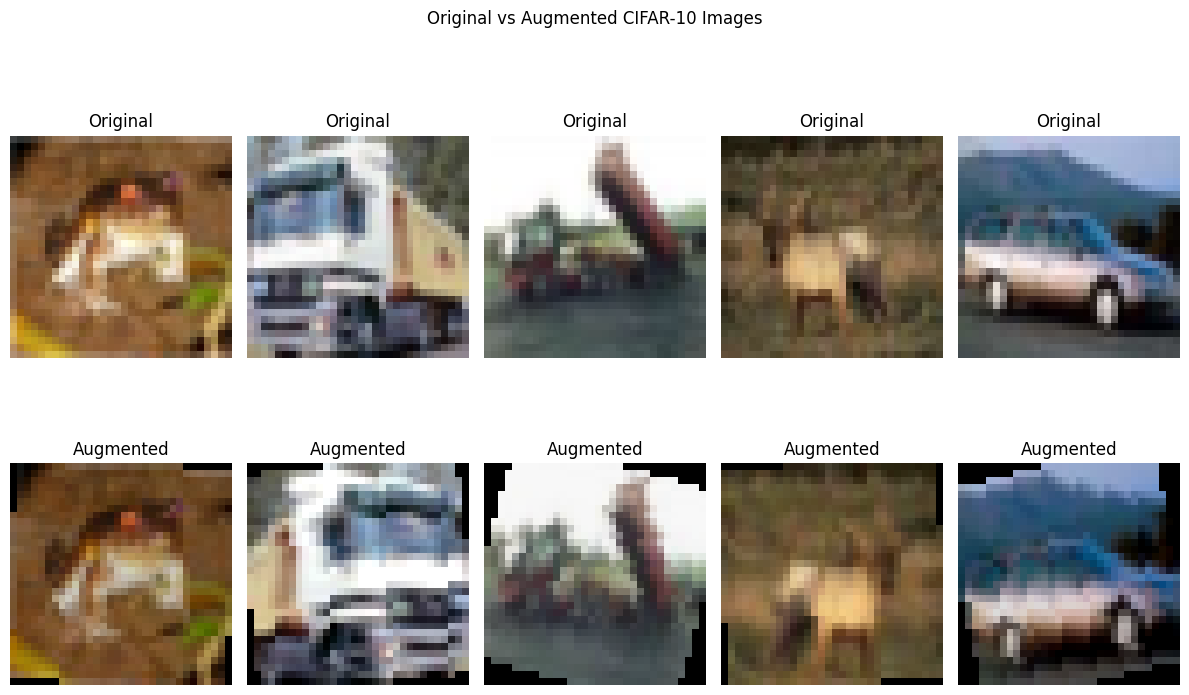

In [12]:

# Task 4: Visualize Data Augmentation

import matplotlib.pyplot as plt

# Load original images as PIL images
original_dataset = CIFAR10(
    root=DATA_PATH,
    train=True,
    download=False,
    transform=None
)

plt.figure(figsize=(12, 8))

for i in range(5):

    image, label = original_dataset[i]

    # Original image
    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title("Original")
    plt.axis("off")

    # Augmented image (without normalization for display)
    display_transform = transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomResizedCrop(32, scale=(0.8, 1.0)),
        transforms.ColorJitter(
            brightness=0.2,
            contrast=0.2,
            saturation=0.2
        ),
        transforms.RandomRotation(15)
    ])

    augmented_image = display_transform(image)

    plt.subplot(2, 5, i + 6)
    plt.imshow(augmented_image)
    plt.title("Augmented")
    plt.axis("off")

plt.suptitle("Original vs Augmented CIFAR-10 Images")
plt.tight_layout()
plt.show()


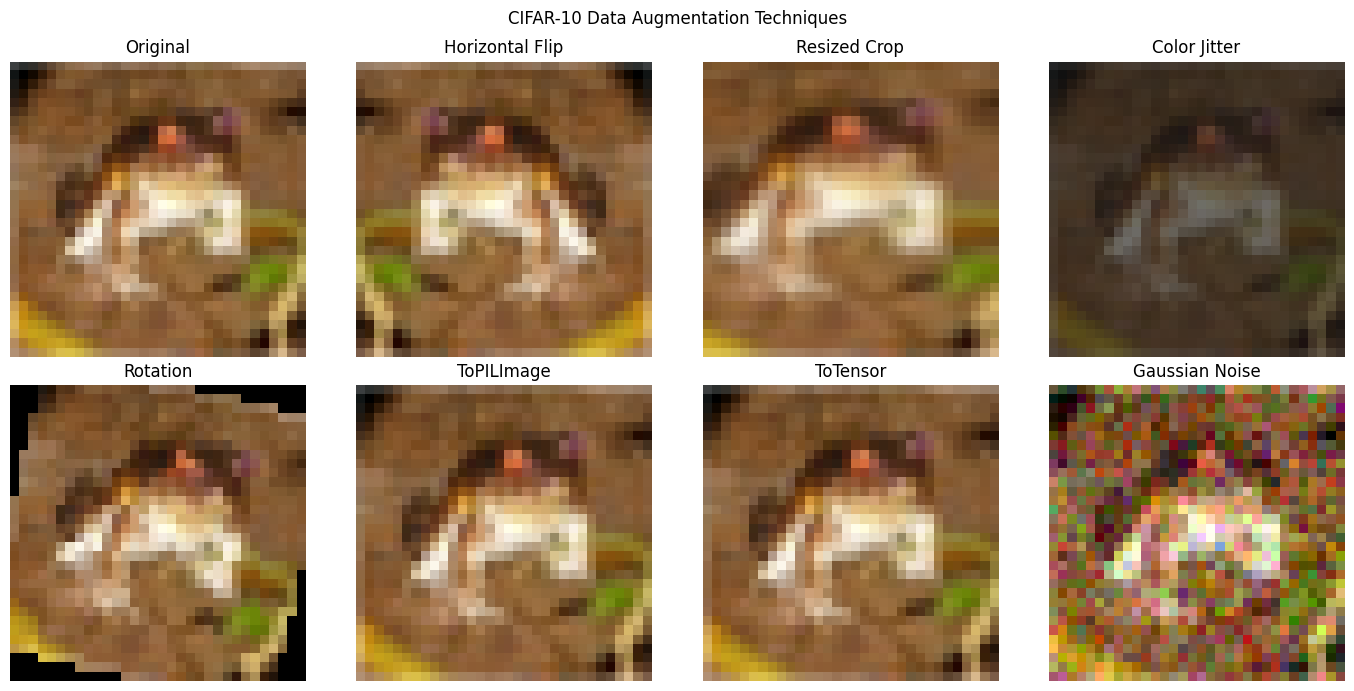

In [13]:

# Task 4: Individual Augmentation Examples

import torch

original_image, label = original_dataset[0]

# Convert PIL image to tensor
image_tensor = transforms.ToTensor()(original_image)

# Convert tensor back to PIL image
image_pil = transforms.ToPILImage()(image_tensor)

# Add Gaussian noise to tensor
noise = torch.randn_like(image_tensor) * 0.1
noisy_image = torch.clamp(image_tensor + noise, 0, 1)

examples = [
    ("Original", original_image),
    ("Horizontal Flip",
     transforms.RandomHorizontalFlip(p=1.0)(original_image)),
    ("Resized Crop",
     transforms.RandomResizedCrop(32)(original_image)),
    ("Color Jitter",
     transforms.ColorJitter(brightness=0.5,
                            contrast=0.5)(original_image)),
    ("Rotation",
     transforms.RandomRotation(25)(original_image)),
    ("ToPILImage", image_pil),
    ("ToTensor", image_tensor.permute(1, 2, 0)),
    ("Gaussian Noise", noisy_image.permute(1, 2, 0))
]

plt.figure(figsize=(14, 7))

for i, (title, image) in enumerate(examples):
    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")

plt.suptitle("CIFAR-10 Data Augmentation Techniques")
plt.tight_layout()
plt.show()


In [14]:

# Task 4: Create Augmented DataLoaders

augmented_train_dataset = CIFAR10(
    root=DATA_PATH,
    train=True,
    download=False,
    transform=train_transform
)

normalized_test_dataset = CIFAR10(
    root=DATA_PATH,
    train=False,
    download=False,
    transform=test_transform
)

augmented_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=32,
    shuffle=True
)

normalized_test_loader = DataLoader(
    normalized_test_dataset,
    batch_size=32,
    shuffle=False
)

# Verify augmented image shapes
images, labels = next(iter(augmented_train_loader))

print("Augmented Images Shape:", images.shape)
print("Labels Shape:", labels.shape)
print("Augmented Training Images:", len(augmented_train_dataset))
print("Normalized Test Images:", len(normalized_test_dataset))

print("\nAugmented DataLoaders Created Successfully!")


Augmented Images Shape: torch.Size([32, 3, 32, 32])
Labels Shape: torch.Size([32])
Augmented Training Images: 50000
Normalized Test Images: 10000

Augmented DataLoaders Created Successfully!


In [15]:

# Task 4: Check Normalization

images, labels = next(iter(normalized_test_loader))

print("Normalized Batch Shape:", images.shape)
print("Minimum Pixel Value:", images.min().item())
print("Maximum Pixel Value:", images.max().item())

print("Mean per Channel:",
      images.mean(dim=(0, 2, 3)).tolist())

print("Standard Deviation per Channel:",
      images.std(dim=(0, 2, 3)).tolist())


Normalized Batch Shape: torch.Size([32, 3, 32, 32])
Minimum Pixel Value: -1.9894737005233765
Maximum Pixel Value: 2.12648868560791
Mean per Channel: [-0.02466636523604393, -0.03204236924648285, -0.05068675056099892]
Standard Deviation per Channel: [1.0062435865402222, 1.0360304117202759, 1.0002646446228027]


In [16]:

# Task 5: Baseline CNN Training Configuration

torch.manual_seed(42)

# Instantiate a fresh CNN model
baseline_model = CNNModel().to(device)

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    baseline_model.parameters(),
    lr=0.001
)

# Number of epochs
num_epochs = 5

# Store training metrics
train_losses = []
train_accuracies = []
test_losses = []
test_accuracies = []

print("Baseline CNN ready for training!")
print("Device:", device)
print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Epochs:", num_epochs)


Baseline CNN ready for training!
Device: cuda
Optimizer: Adam
Learning Rate: 0.001
Epochs: 5


In [17]:

# Task 5: Train Baseline CNN

for epoch in range(num_epochs):

    train_loss, train_accuracy = train_one_epoch(
        baseline_model,
        augmented_train_loader,
        criterion,
        optimizer,
        device
    )

    test_loss, test_accuracy = evaluate_model(
        baseline_model,
        normalized_test_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

print("\nBaseline Training Completed!")


Epoch [1/5] Train Loss: 1.5126 | Train Accuracy: 45.41% | Test Loss: 1.2504 | Test Accuracy: 54.53%
Epoch [2/5] Train Loss: 1.2412 | Train Accuracy: 56.01% | Test Loss: 1.0746 | Test Accuracy: 61.70%
Epoch [3/5] Train Loss: 1.1420 | Train Accuracy: 59.62% | Test Loss: 1.0488 | Test Accuracy: 62.23%
Epoch [4/5] Train Loss: 1.0775 | Train Accuracy: 62.02% | Test Loss: 0.9450 | Test Accuracy: 66.41%
Epoch [5/5] Train Loss: 1.0385 | Train Accuracy: 63.09% | Test Loss: 0.9600 | Test Accuracy: 66.21%

Baseline Training Completed!


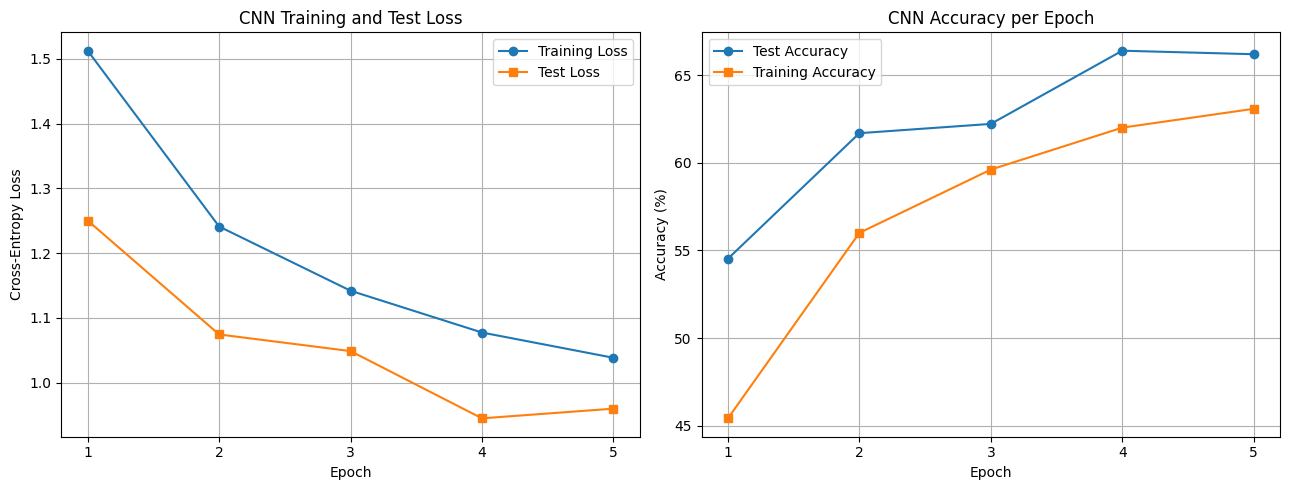

In [18]:

# Task 5: Plot Baseline Training Results

epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses,
         marker='o', label="Training Loss")
plt.plot(epochs_range, test_losses,
         marker='s', label="Test Loss")
plt.title("CNN Training and Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, test_accuracies,
         marker='o', label="Test Accuracy")
plt.plot(epochs_range, train_accuracies,
         marker='s', label="Training Accuracy")
plt.title("CNN Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [19]:

# Task 5: Create Train and Validation Split

from torch.utils.data import Subset, DataLoader

torch.manual_seed(42)

# Fixed, reproducible split
generator = torch.Generator().manual_seed(42)

indices = torch.randperm(
    len(augmented_train_dataset),
    generator=generator
).tolist()

train_indices = indices[:40000]
val_indices = indices[40000:]

# Training subset uses augmentation
tuning_train_dataset = Subset(
    augmented_train_dataset,
    train_indices
)

# Validation uses normalization only
validation_dataset = CIFAR10(
    root=DATA_PATH,
    train=True,
    download=False,
    transform=test_transform
)

validation_subset = Subset(
    validation_dataset,
    val_indices
)

tuning_train_loader = DataLoader(
    tuning_train_dataset,
    batch_size=64,
    shuffle=True
)

validation_loader = DataLoader(
    validation_subset,
    batch_size=64,
    shuffle=False
)

print("Training samples:", len(tuning_train_dataset))
print("Validation samples:", len(validation_subset))


Training samples: 40000
Validation samples: 10000


In [20]:

# Task 5: Learning Rate Experiments

import pandas as pd

learning_rates = [0.0001, 0.001, 0.01]
lr_results = []

for lr in learning_rates:

    print(f"\nTraining with learning rate: {lr}")

    torch.manual_seed(42)

    experiment_model = CNNModel().to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        experiment_model.parameters(),
        lr=lr
    )

    for epoch in range(3):

        train_loss, train_acc = train_one_epoch(
            experiment_model,
            tuning_train_loader,
            criterion,
            optimizer,
            device
        )

        val_loss, val_acc = evaluate_model(
            experiment_model,
            validation_loader,
            criterion,
            device
        )

        print(
            f"Epoch {epoch+1}/3 | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_acc:.2f}%"
        )

    lr_results.append({
        "Learning Rate": lr,
        "Train Loss": train_loss,
        "Validation Loss": val_loss,
        "Validation Accuracy (%)": val_acc
    })

lr_df = pd.DataFrame(lr_results)

print("\nLearning Rate Comparison:")
print(lr_df.to_string(index=False))



Training with learning rate: 0.0001
Epoch 1/3 | Train Loss: 1.8766 | Val Loss: 1.6851 | Val Accuracy: 39.87%
Epoch 2/3 | Train Loss: 1.6033 | Val Loss: 1.5032 | Val Accuracy: 46.80%
Epoch 3/3 | Train Loss: 1.5025 | Val Loss: 1.4170 | Val Accuracy: 49.59%

Training with learning rate: 0.001
Epoch 1/3 | Train Loss: 1.6027 | Val Loss: 1.3317 | Val Accuracy: 52.17%
Epoch 2/3 | Train Loss: 1.3338 | Val Loss: 1.1525 | Val Accuracy: 59.12%
Epoch 3/3 | Train Loss: 1.2250 | Val Loss: 1.0789 | Val Accuracy: 61.72%

Training with learning rate: 0.01
Epoch 1/3 | Train Loss: 1.9033 | Val Loss: 1.6960 | Val Accuracy: 37.35%
Epoch 2/3 | Train Loss: 1.7422 | Val Loss: 1.6046 | Val Accuracy: 40.99%
Epoch 3/3 | Train Loss: 1.6637 | Val Loss: 1.5511 | Val Accuracy: 43.88%

Learning Rate Comparison:
 Learning Rate  Train Loss  Validation Loss  Validation Accuracy (%)
        0.0001    1.502479         1.416984                    49.59
        0.0010    1.224973         1.078885                    61.72
 

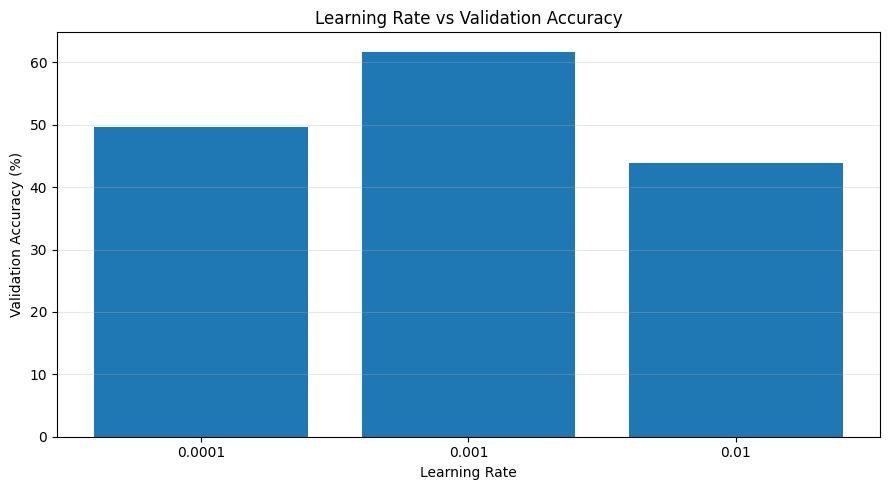

Best Learning Rate: 0.001
Validation Accuracy: 61.72%


In [21]:

# Task 5: Learning Rate Comparison Graph

plt.figure(figsize=(9, 5))

plt.bar(
    lr_df["Learning Rate"].astype(str),
    lr_df["Validation Accuracy (%)"]
)

plt.title("Learning Rate vs Validation Accuracy")
plt.xlabel("Learning Rate")
plt.ylabel("Validation Accuracy (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

best_lr_row = lr_df.sort_values(
    by=["Validation Accuracy (%)", "Validation Loss"],
    ascending=[False, True]
).iloc[0]

best_lr = float(best_lr_row["Learning Rate"])

print("Best Learning Rate:", best_lr)
print(
    "Validation Accuracy:",
    f"{best_lr_row['Validation Accuracy (%)']:.2f}%"
)


In [22]:

# Task 5: Batch Size Tuning

batch_sizes = [32, 64, 128]
batch_results = []

for batch_size in batch_sizes:

    print(f"\nTraining with batch size: {batch_size}")

    torch.manual_seed(42)

    experiment_model = CNNModel().to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        experiment_model.parameters(),
        lr=best_lr
    )

    experiment_train_loader = DataLoader(
        tuning_train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    experiment_val_loader = DataLoader(
        validation_subset,
        batch_size=batch_size,
        shuffle=False
    )

    for epoch in range(3):

        train_loss, train_acc = train_one_epoch(
            experiment_model,
            experiment_train_loader,
            criterion,
            optimizer,
            device
        )

        val_loss, val_acc = evaluate_model(
            experiment_model,
            experiment_val_loader,
            criterion,
            device
        )

        print(
            f"Epoch {epoch+1}/3 | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_acc:.2f}%"
        )

    batch_results.append({
        "Batch Size": batch_size,
        "Train Loss": train_loss,
        "Validation Loss": val_loss,
        "Validation Accuracy (%)": val_acc
    })

batch_df = pd.DataFrame(batch_results)

print("\nBatch Size Comparison:")
print(batch_df.to_string(index=False))



Training with batch size: 32
Epoch 1/3 | Train Loss: 1.5663 | Val Loss: 1.3146 | Val Accuracy: 52.88%
Epoch 2/3 | Train Loss: 1.2876 | Val Loss: 1.1239 | Val Accuracy: 59.19%
Epoch 3/3 | Train Loss: 1.1816 | Val Loss: 1.0363 | Val Accuracy: 63.25%

Training with batch size: 64
Epoch 1/3 | Train Loss: 1.6031 | Val Loss: 1.3310 | Val Accuracy: 52.22%
Epoch 2/3 | Train Loss: 1.3332 | Val Loss: 1.1551 | Val Accuracy: 58.74%
Epoch 3/3 | Train Loss: 1.2273 | Val Loss: 1.0805 | Val Accuracy: 61.72%

Training with batch size: 128
Epoch 1/3 | Train Loss: 1.6523 | Val Loss: 1.3657 | Val Accuracy: 50.65%
Epoch 2/3 | Train Loss: 1.3725 | Val Loss: 1.2308 | Val Accuracy: 56.09%
Epoch 3/3 | Train Loss: 1.2719 | Val Loss: 1.1342 | Val Accuracy: 59.89%

Batch Size Comparison:
 Batch Size  Train Loss  Validation Loss  Validation Accuracy (%)
         32    1.181560         1.036307                    63.25
         64    1.227259         1.080461                    61.72
        128    1.271909       

In [23]:

# Task 5: Optimizer Comparison

optimizer_results = []

for optimizer_name in ["Adam", "SGD"]:

    print(f"\nTraining with optimizer: {optimizer_name}")

    torch.manual_seed(42)

    experiment_model = CNNModel().to(device)
    criterion = nn.CrossEntropyLoss()

    if optimizer_name == "Adam":
        optimizer = optim.Adam(
            experiment_model.parameters(),
            lr=best_lr
        )
    else:
        optimizer = optim.SGD(
            experiment_model.parameters(),
            lr=best_lr,
            momentum=0.9
        )

    for epoch in range(3):

        train_loss, train_acc = train_one_epoch(
            experiment_model,
            tuning_train_loader,
            criterion,
            optimizer,
            device
        )

        val_loss, val_acc = evaluate_model(
            experiment_model,
            validation_loader,
            criterion,
            device
        )

        print(
            f"Epoch {epoch+1}/3 | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_acc:.2f}%"
        )

    optimizer_results.append({
        "Optimizer": optimizer_name,
        "Train Loss": train_loss,
        "Validation Loss": val_loss,
        "Validation Accuracy (%)": val_acc
    })

optimizer_df = pd.DataFrame(optimizer_results)

print("\nOptimizer Comparison:")
print(optimizer_df.to_string(index=False))



Training with optimizer: Adam
Epoch 1/3 | Train Loss: 1.6027 | Val Loss: 1.3366 | Val Accuracy: 52.01%
Epoch 2/3 | Train Loss: 1.3347 | Val Loss: 1.1567 | Val Accuracy: 58.93%
Epoch 3/3 | Train Loss: 1.2277 | Val Loss: 1.0786 | Val Accuracy: 61.76%

Training with optimizer: SGD
Epoch 1/3 | Train Loss: 2.0719 | Val Loss: 1.8876 | Val Accuracy: 32.95%
Epoch 2/3 | Train Loss: 1.7816 | Val Loss: 1.6534 | Val Accuracy: 41.17%
Epoch 3/3 | Train Loss: 1.6187 | Val Loss: 1.5434 | Val Accuracy: 45.19%

Optimizer Comparison:
Optimizer  Train Loss  Validation Loss  Validation Accuracy (%)
     Adam    1.227712         1.078633                    61.76
      SGD    1.618720         1.543423                    45.19


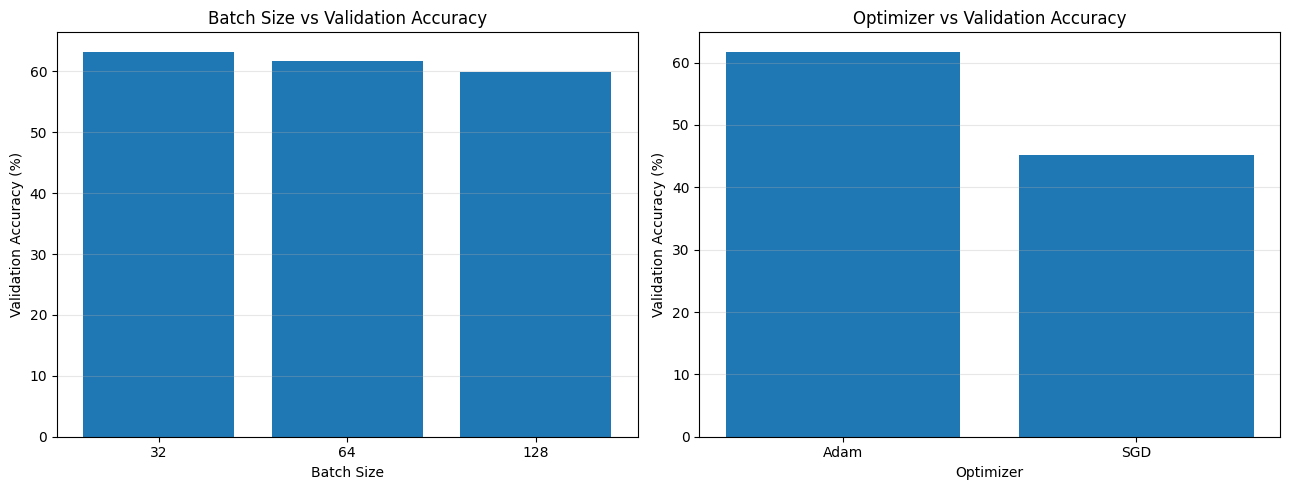

In [24]:

# Task 5: Batch Size and Optimizer Graphs

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    batch_df["Batch Size"].astype(str),
    batch_df["Validation Accuracy (%)"]
)

axes[0].set_title("Batch Size vs Validation Accuracy")
axes[0].set_xlabel("Batch Size")
axes[0].set_ylabel("Validation Accuracy (%)")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    optimizer_df["Optimizer"],
    optimizer_df["Validation Accuracy (%)"]
)

axes[1].set_title("Optimizer vs Validation Accuracy")
axes[1].set_xlabel("Optimizer")
axes[1].set_ylabel("Validation Accuracy (%)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [25]:

# Task 5: CNN Architecture Experiments

class FlexibleCNN(nn.Module):
    def __init__(self, filters1=16, filters2=32):
        super(FlexibleCNN, self).__init__()

        self.conv1 = nn.Conv2d(
            3, filters1, kernel_size=3, padding=1
        )

        self.conv2 = nn.Conv2d(
            filters1, filters2, kernel_size=3, padding=1
        )

        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()

        self.fc1 = nn.Linear(filters2 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x


print("Flexible CNN Architecture Defined!")


Flexible CNN Architecture Defined!


In [26]:

# Task 5: Architecture Comparison

architectures = [
    ("Small CNN", 8, 16),
    ("Original CNN", 16, 32),
    ("Larger CNN", 32, 64)
]

architecture_results = []

# Use batch size 32
architecture_train_loader = DataLoader(
    tuning_train_dataset,
    batch_size=32,
    shuffle=True
)

architecture_val_loader = DataLoader(
    validation_subset,
    batch_size=32,
    shuffle=False
)

for name, filters1, filters2 in architectures:

    print(f"\nTraining {name}: {filters1}, {filters2} filters")

    torch.manual_seed(42)

    experiment_model = FlexibleCNN(
        filters1=filters1,
        filters2=filters2
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        experiment_model.parameters(),
        lr=0.001
    )

    for epoch in range(3):

        train_loss, train_acc = train_one_epoch(
            experiment_model,
            architecture_train_loader,
            criterion,
            optimizer,
            device
        )

        val_loss, val_acc = evaluate_model(
            experiment_model,
            architecture_val_loader,
            criterion,
            device
        )

        print(
            f"Epoch {epoch+1}/3 | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_acc:.2f}%"
        )

    architecture_results.append({
        "Architecture": name,
        "Filters 1": filters1,
        "Filters 2": filters2,
        "Train Loss": train_loss,
        "Validation Loss": val_loss,
        "Validation Accuracy (%)": val_acc
    })

architecture_df = pd.DataFrame(architecture_results)

print("\nArchitecture Comparison:")
print(architecture_df.to_string(index=False))



Training Small CNN: 8, 16 filters
Epoch 1/3 | Train Loss: 1.6291 | Val Loss: 1.3890 | Val Accuracy: 49.23%
Epoch 2/3 | Train Loss: 1.3985 | Val Loss: 1.2852 | Val Accuracy: 54.33%
Epoch 3/3 | Train Loss: 1.3076 | Val Loss: 1.2492 | Val Accuracy: 56.00%

Training Original CNN: 16, 32 filters
Epoch 1/3 | Train Loss: 1.5657 | Val Loss: 1.3243 | Val Accuracy: 52.20%
Epoch 2/3 | Train Loss: 1.2872 | Val Loss: 1.1240 | Val Accuracy: 59.15%
Epoch 3/3 | Train Loss: 1.1807 | Val Loss: 1.0155 | Val Accuracy: 64.38%

Training Larger CNN: 32, 64 filters
Epoch 1/3 | Train Loss: 1.5405 | Val Loss: 1.2051 | Val Accuracy: 56.65%
Epoch 2/3 | Train Loss: 1.2444 | Val Loss: 1.0455 | Val Accuracy: 62.60%
Epoch 3/3 | Train Loss: 1.1405 | Val Loss: 1.0100 | Val Accuracy: 64.31%

Architecture Comparison:
Architecture  Filters 1  Filters 2  Train Loss  Validation Loss  Validation Accuracy (%)
   Small CNN          8         16    1.307636         1.249166                    56.00
Original CNN         16     

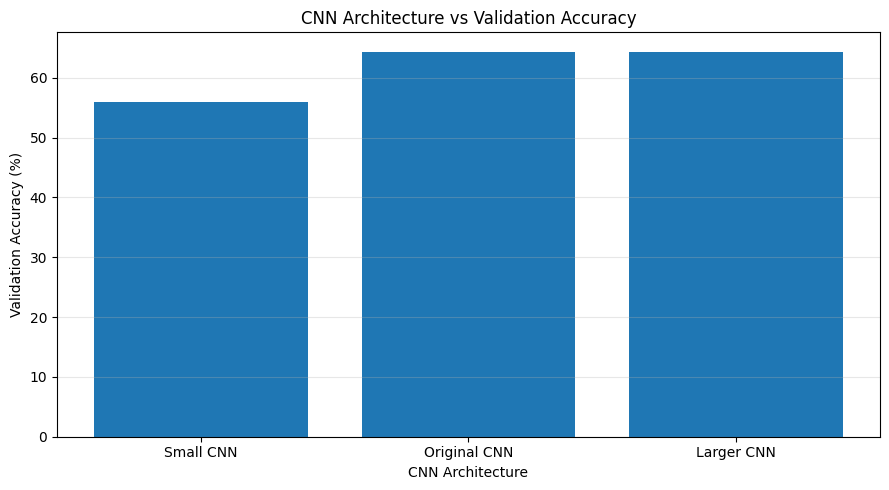

Best CNN Architecture: Original CNN
Best Validation Accuracy: 64.38%


In [27]:

# Task 5: Architecture Accuracy Comparison

plt.figure(figsize=(9, 5))

plt.bar(
    architecture_df["Architecture"],
    architecture_df["Validation Accuracy (%)"]
)

plt.title("CNN Architecture vs Validation Accuracy")
plt.xlabel("CNN Architecture")
plt.ylabel("Validation Accuracy (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

best_architecture_row = architecture_df.sort_values(
    by=["Validation Accuracy (%)", "Validation Loss"],
    ascending=[False, True]
).iloc[0]

print("Best CNN Architecture:",
      best_architecture_row["Architecture"])

print(
    "Best Validation Accuracy:",
    f"{best_architecture_row['Validation Accuracy (%)']:.2f}%"
)


In [28]:

# Task 5: Compare Training With and Without Augmentation

from torch.utils.data import Subset, DataLoader

# Dataset without augmentation, but with normalization
no_aug_dataset = CIFAR10(
    root=DATA_PATH,
    train=True,
    download=False,
    transform=test_transform
)

# Use the same 40,000 training indices from Cell 19
no_aug_subset = Subset(no_aug_dataset, train_indices)

no_aug_loader = DataLoader(
    no_aug_subset,
    batch_size=32,
    shuffle=True
)

# Dataset with augmentation
with_aug_loader = DataLoader(
    tuning_train_dataset,
    batch_size=32,
    shuffle=True
)

print("Without Augmentation:", len(no_aug_subset))
print("With Augmentation:", len(tuning_train_dataset))


Without Augmentation: 40000
With Augmentation: 40000


In [29]:

# Task 5: Data Augmentation Experiment

augmentation_results = []

experiments = [
    ("Without Augmentation", no_aug_loader),
    ("With Augmentation", with_aug_loader)
]

for name, loader in experiments:

    print(f"\nTraining: {name}")

    torch.manual_seed(42)

    experiment_model = CNNModel().to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        experiment_model.parameters(),
        lr=0.001
    )

    for epoch in range(3):

        train_loss, train_acc = train_one_epoch(
            experiment_model,
            loader,
            criterion,
            optimizer,
            device
        )

        val_loss, val_acc = evaluate_model(
            experiment_model,
            architecture_val_loader,
            criterion,
            device
        )

        print(
            f"Epoch {epoch+1}/3 | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_acc:.2f}%"
        )

    augmentation_results.append({
        "Augmentation": name,
        "Train Loss": train_loss,
        "Validation Loss": val_loss,
        "Validation Accuracy (%)": val_acc
    })

augmentation_df = pd.DataFrame(augmentation_results)

print("\nAugmentation Comparison:")
print(augmentation_df.to_string(index=False))



Training: Without Augmentation
Epoch 1/3 | Train Loss: 1.3787 | Val Loss: 1.1398 | Val Accuracy: 59.28%
Epoch 2/3 | Train Loss: 1.0417 | Val Loss: 1.0271 | Val Accuracy: 63.43%
Epoch 3/3 | Train Loss: 0.8926 | Val Loss: 0.9445 | Val Accuracy: 66.38%

Training: With Augmentation
Epoch 1/3 | Train Loss: 1.5669 | Val Loss: 1.3188 | Val Accuracy: 52.35%
Epoch 2/3 | Train Loss: 1.2853 | Val Loss: 1.1084 | Val Accuracy: 59.78%
Epoch 3/3 | Train Loss: 1.1803 | Val Loss: 1.0215 | Val Accuracy: 63.72%

Augmentation Comparison:
        Augmentation  Train Loss  Validation Loss  Validation Accuracy (%)
Without Augmentation    0.892582         0.944549                    66.38
   With Augmentation    1.180326         1.021507                    63.72


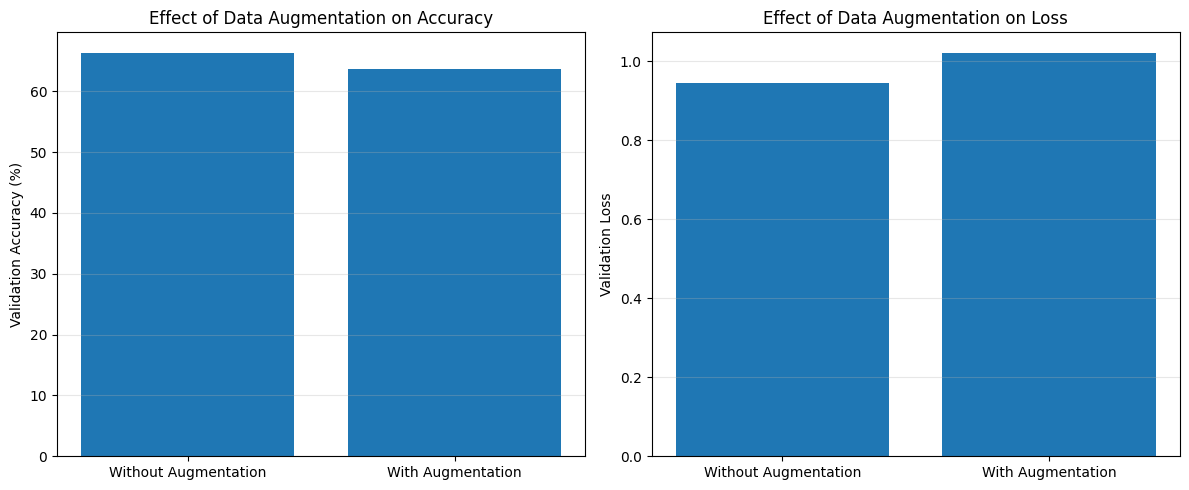

In [30]:

# Task 5: Augmentation Comparison Graph

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(
    augmentation_df["Augmentation"],
    augmentation_df["Validation Accuracy (%)"]
)
axes[0].set_title("Effect of Data Augmentation on Accuracy")
axes[0].set_ylabel("Validation Accuracy (%)")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    augmentation_df["Augmentation"],
    augmentation_df["Validation Loss"]
)
axes[1].set_title("Effect of Data Augmentation on Loss")
axes[1].set_ylabel("Validation Loss")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [31]:
# Final Training Setup using Best Configuration

final_train_dataset = CIFAR10(
    root=DATA_PATH,
    train=True,
    download=False,
    transform=test_transform   # no augmentation, normalization only
)

final_test_dataset = CIFAR10(
    root=DATA_PATH,
    train=False,
    download=False,
    transform=test_transform
)

final_train_loader = DataLoader(
    final_train_dataset,
    batch_size=32,
    shuffle=True
)

final_test_loader = DataLoader(
    final_test_dataset,
    batch_size=32,
    shuffle=False
)

print("Final training images:", len(final_train_dataset))
print("Final testing images:", len(final_test_dataset))

Final training images: 50000
Final testing images: 10000


In [32]:
# Final Model

torch.manual_seed(42)

final_model = CNNModel().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    final_model.parameters(),
    lr=0.001
)

final_num_epochs = 5

final_train_losses = []
final_train_accuracies = []
final_test_losses = []
final_test_accuracies = []

print("Final model initialized successfully!")

Final model initialized successfully!


In [33]:
# Train Final Model

for epoch in range(final_num_epochs):

    train_loss, train_accuracy = train_one_epoch(
        final_model,
        final_train_loader,
        criterion,
        optimizer,
        device
    )

    test_loss, test_accuracy = evaluate_model(
        final_model,
        final_test_loader,
        criterion,
        device
    )

    final_train_losses.append(train_loss)
    final_train_accuracies.append(train_accuracy)
    final_test_losses.append(test_loss)
    final_test_accuracies.append(test_accuracy)

    print(
        f"Epoch [{epoch+1}/{final_num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

print("\nFinal training completed!")

Epoch [1/5] | Train Loss: 1.3298 | Train Accuracy: 52.10% | Test Loss: 1.0906 | Test Accuracy: 61.38%
Epoch [2/5] | Train Loss: 0.9956 | Train Accuracy: 64.86% | Test Loss: 0.9786 | Test Accuracy: 65.30%
Epoch [3/5] | Train Loss: 0.8625 | Train Accuracy: 69.73% | Test Loss: 0.9292 | Test Accuracy: 67.93%
Epoch [4/5] | Train Loss: 0.7660 | Train Accuracy: 73.06% | Test Loss: 0.9120 | Test Accuracy: 68.36%
Epoch [5/5] | Train Loss: 0.6870 | Train Accuracy: 75.81% | Test Loss: 0.9067 | Test Accuracy: 69.37%

Final training completed!


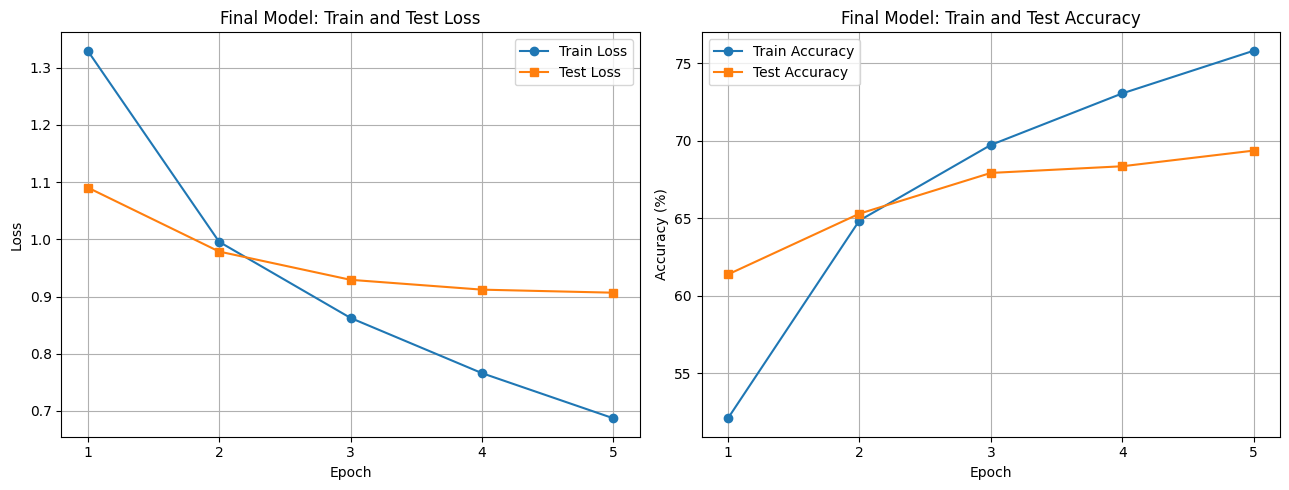

In [34]:
# Plot Final Results

epochs_range = range(1, final_num_epochs + 1)

plt.figure(figsize=(13, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, final_train_losses, marker='o', label='Train Loss')
plt.plot(epochs_range, final_test_losses, marker='s', label='Test Loss')
plt.title("Final Model: Train and Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, final_train_accuracies, marker='o', label='Train Accuracy')
plt.plot(epochs_range, final_test_accuracies, marker='s', label='Test Accuracy')
plt.title("Final Model: Train and Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [35]:
# Final Best Results Summary

best_test_accuracy = max(final_test_accuracies)
best_epoch = final_test_accuracies.index(best_test_accuracy) + 1

print("FINAL RESULTS")
print("Best Configuration:")
print(" - Architecture: Original CNN (16 -> 32 filters)")
print(" - Optimizer: Adam")
print(" - Learning Rate: 0.001")
print(" - Batch Size: 32")
print(" - Augmentation: No")

print(f"\nFinal Train Loss (last epoch): {final_train_losses[-1]:.4f}")
print(f"Final Test Loss (last epoch): {final_test_losses[-1]:.4f}")
print(f"Final Test Accuracy (last epoch): {final_test_accuracies[-1]:.2f}%")

print(f"\nBest Test Accuracy: {best_test_accuracy:.2f}%")
print(f"Best Epoch: {best_epoch}")

FINAL RESULTS
Best Configuration:
 - Architecture: Original CNN (16 -> 32 filters)
 - Optimizer: Adam
 - Learning Rate: 0.001
 - Batch Size: 32
 - Augmentation: No

Final Train Loss (last epoch): 0.6870
Final Test Loss (last epoch): 0.9067
Final Test Accuracy (last epoch): 69.37%

Best Test Accuracy: 69.37%
Best Epoch: 5


In [36]:
# Optional: Save trained model

torch.save(final_model.state_dict(), "cnn_cifar10_final_model.pth")
print("Model saved as cnn_cifar10_final_model.pth")

Model saved as cnn_cifar10_final_model.pth


In [37]:

# Task 6: Save Final Model and Experiment Results

import torch
import pandas as pd

# Save model weights
torch.save(
    final_model.state_dict(),
    "cnn_cifar10_final_model.pth"
)

# Save epoch-by-epoch training results
final_results_df = pd.DataFrame({
    "Epoch": list(range(1, final_num_epochs + 1)),
    "Train Loss": final_train_losses,
    "Train Accuracy (%)": final_train_accuracies,
    "Test Loss": final_test_losses,
    "Test Accuracy (%)": final_test_accuracies
})

final_results_df.to_csv(
    "cnn_cifar10_training_results.csv",
    index=False
)

print("Model and results saved successfully!")
print(final_results_df.to_string(index=False))


Model and results saved successfully!
 Epoch  Train Loss  Train Accuracy (%)  Test Loss  Test Accuracy (%)
     1    1.329826              52.098   1.090573              61.38
     2    0.995637              64.860   0.978626              65.30
     3    0.862499              69.734   0.929189              67.93
     4    0.765951              73.060   0.912003              68.36
     5    0.686964              75.814   0.906673              69.37


## Conclusion

In this assignment, a Convolutional Neural Network (CNN) was developed using PyTorch to classify images from the CIFAR-10 dataset.

The network incorporated convolutional layers, ReLU activation functions, max-pooling layers, and fully connected layers.

Several experiments were conducted to investigate the effects of learning rate, batch size, optimizer, network architecture, and data augmentation.

The experiments showed that the most effective tested configuration used:

- **CNN Architecture:** 16 and 32 convolutional filters
- **Optimizer:** Adam
- **Learning Rate:** 0.001
- **Batch Size:** 32
- **Training Epochs:** 5
- **Data Augmentation:** No random augmentation; normalization only

The final model achieved **75.81% training accuracy** and **69.37% test accuracy**, with a training loss of **0.6870** and test loss of **0.9067**.

The results demonstrate that the CNN successfully learned to classify CIFAR-10 images. They also show that model performance depends on the choice of hyperparameters and training strategy. Although the final model achieved reasonable classification performance, the difference between training and test accuracy suggests that further improvements in generalization may be possible.